# Problema 2 — Clasificación de imágenes de futbolistas (Golden Foot)

**Objetivo.** Dada una imagen, identificar a cuál de los **22 futbolistas** del dataset corresponde, con
**Recall > 0.9** y **F1-score > 0.9** (promedio *macro*, es decir, cada jugador pesa lo mismo).

**Fuente:** Kaggle — `balabaskar/golden-foot-football-players-image-dataset` (≈7 200 imágenes, un directorio por
jugador y un CSV `folder_name, filename` que relaciona cada imagen con el futbolista).

> ⚙️ **Ejecutar en Google Colab con GPU:** *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*.
> Tiempo aproximado total: 20–30 min.

**Resumen de la solución — modelo en conjunto (ensemble)**

Las imágenes son fotos reales tomadas de internet: cuerpo entero, primeros planos, varias personas, camisetas,
fotos antiguas en blanco y negro. Por eso se combinan dos modelos complementarios mediante *transfer learning*:

| Modelo | Idea | Qué aporta |
|---|---|---|
| **A. CLIP ViT-L/14 + Regresión logística** | Red Transformer preentrenada por OpenAI con 400 M de pares imagen-texto; se usa como extractor de características (embeddings de 768 dimensiones) y se entrena un clasificador lineal encima | Reconoce rostros, camisetas y contexto; muy robusta con pocos datos |
| **B. ConvNeXt-Small afinada (fine-tuning)** | Red convolucional preentrenada en ImageNet-22k, se reentrena completa con *data augmentation* | Aprende rasgos visuales específicos de este dataset |
| **Ensemble** | Promedio ponderado de las probabilidades (*soft voting*); el peso se elige en validación | Combina errores poco correlacionados → mejor recall y F1 |

In [1]:
!pip -q install open_clip_torch timm

In [2]:
import os, glob, hashlib, random, warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as Tr
import open_clip, timm, kagglehub
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, recall_score, f1_score, accuracy_score,
                             precision_score, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo:', device, torch.cuda.get_device_name(0) if device == 'cuda' else '(activa la GPU en Colab)')

Dispositivo: cuda Tesla T4


## 1. Carga del dataset y relación CSV ↔ imágenes

In [3]:
ruta = kagglehub.dataset_download('balabaskar/golden-foot-football-players-image-dataset')
csv_path = glob.glob(os.path.join(ruta, '**', '*.csv'), recursive=True)[0]
meta = pd.read_csv(csv_path)
print('Filas vacías en el CSV (se descartan):', meta[['folder_name', 'filename']].isna().any(axis=1).sum())
meta = meta.dropna(subset=['folder_name', 'filename']).reset_index(drop=True)
# Carpeta raíz que contiene un subdirectorio por jugador
img_root = [os.path.dirname(os.path.dirname(p)) for p in glob.glob(os.path.join(ruta, '**', '*.jpg'), recursive=True)][0]
meta['path'] = meta.apply(lambda r: os.path.join(img_root, r.folder_name, r.filename), axis=1)
meta['existe'] = meta.path.map(os.path.exists)
print('CSV:', csv_path); print('Imágenes:', img_root)
print(f'Filas en CSV: {len(meta)} | archivos encontrados: {meta.existe.sum()}')
meta = meta[meta.existe].reset_index(drop=True)
meta.head()

100%|██████████| 517M/517M [00:08<00:00, 66.7MB/s]

Extracting files...


Filas vacías en el CSV (se descartan): 1
CSV: /root/.cache/kagglehub/datasets/balabaskar/golden-foot-football-players-image-dataset/versions/2/football_golden_foot.csv
Imágenes: /root/.cache/kagglehub/datasets/balabaskar/golden-foot-football-players-image-dataset/versions/2/football_golden_foot/football_golden_foot
Filas en CSV: 7189 | archivos encontrados: 7188


,folder_name,filename,path,existe
0,alessandro_del_piero,0016c4771c.jpg,/root/.cache/kagglehub/datasets/balabaskar/gol...,True
1,alessandro_del_piero,008a84657a.jpg,/root/.cache/kagglehub/datasets/balabaskar/gol...,True
2,alessandro_del_piero,0156ce23f5.jpg,/root/.cache/kagglehub/datasets/balabaskar/gol...,True
3,alessandro_del_piero,04f705db4d.jpg,/root/.cache/kagglehub/datasets/balabaskar/gol...,True
4,alessandro_del_piero,05aa02a997.jpg,/root/.cache/kagglehub/datasets/balabaskar/gol...,True


### Limpieza: imágenes duplicadas
Se calcula el hash MD5 de cada archivo. Las imágenes idénticas que aparecen en **carpetas de jugadores distintos**
tienen una etiqueta contradictoria y se eliminan; los duplicados dentro de la misma carpeta se dejan una sola vez
(si no, una misma foto podría caer en train y en test e inflar las métricas). También se descartan archivos corruptos.

In [4]:
def md5(p):
    with open(p, 'rb') as f: return hashlib.md5(f.read()).hexdigest()
def ok(p):
    try:
        Image.open(p).verify(); return True
    except Exception: return False
meta['md5'] = meta.path.map(md5)
meta['valida'] = meta.path.map(ok)
clases_por_hash = meta.groupby('md5').folder_name.nunique()
conflicto = clases_por_hash[clases_por_hash > 1].index
n0 = len(meta)
meta = meta[~meta.md5.isin(conflicto) & meta.valida].drop_duplicates('md5').reset_index(drop=True)
print(f'Hashes en conflicto entre jugadores: {len(conflicto)} | imágenes: {n0} -> {len(meta)}')

Hashes en conflicto entre jugadores: 7 | imágenes: 7188 -> 7174


## 2. Análisis exploratorio

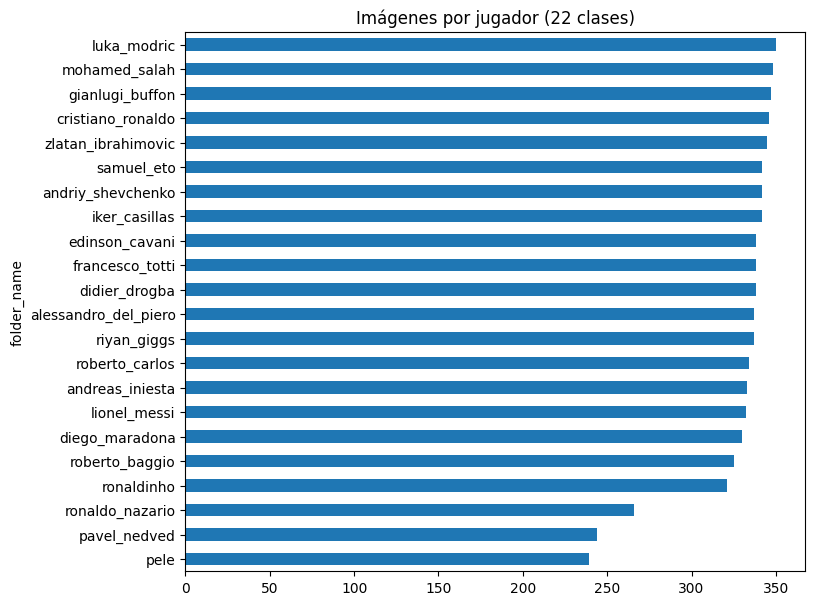

Mín: 239 | Máx: 350 | ratio desbalance: 1.46


In [5]:
CLASES = sorted(meta.folder_name.unique())
idx = {c: i for i, c in enumerate(CLASES)}
meta['y'] = meta.folder_name.map(idx)
NOMBRES = [c.replace('_', ' ').title() for c in CLASES]
conteo = meta.folder_name.value_counts().sort_values()
conteo.plot.barh(figsize=(8, 7), title=f'Imágenes por jugador ({len(CLASES)} clases)'); plt.show()
print('Mín:', conteo.min(), '| Máx:', conteo.max(), '| ratio desbalance:', round(conteo.max() / conteo.min(), 2))

        ancho    alto
count   800.0   800.0
mean    606.0   455.0
std     502.0   383.0
min     157.0   140.0
25%     275.0   182.0
50%     304.0   275.0
75%     871.0   634.0
max    3200.0  2461.0


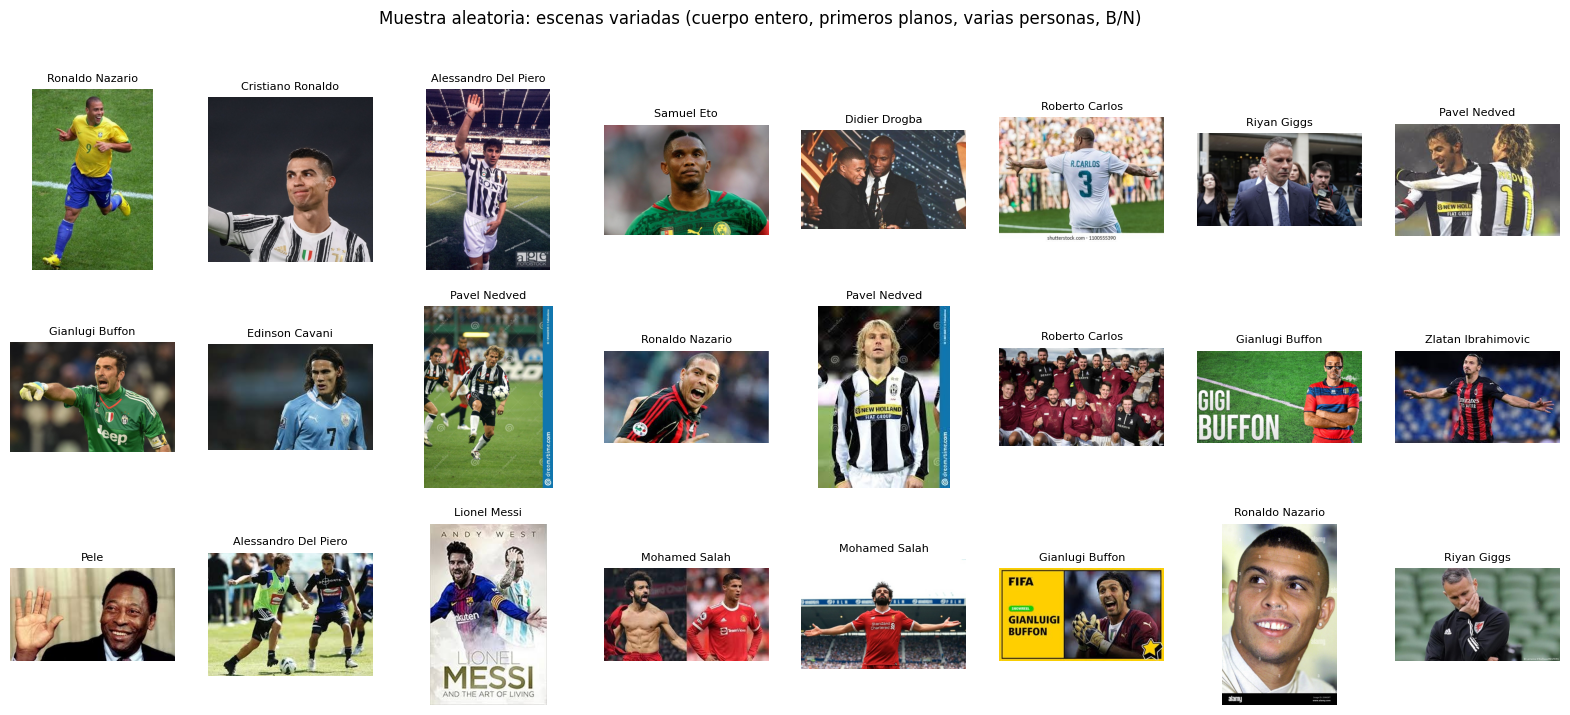

In [6]:
tam = pd.DataFrame([Image.open(p).size for p in meta.path.sample(800, random_state=SEED)], columns=['ancho', 'alto'])
print(tam.describe().round(0))
fig, axes = plt.subplots(3, 8, figsize=(20, 8))
for ax, (_, r) in zip(axes.ravel(), meta.sample(24, random_state=1).iterrows()):
    ax.imshow(Image.open(r.path).convert('RGB')); ax.set_title(NOMBRES[r.y], fontsize=8); ax.axis('off')
plt.suptitle('Muestra aleatoria: escenas variadas (cuerpo entero, primeros planos, varias personas, B/N)'); plt.show()

**Observaciones**
- Clases razonablemente balanceadas (≈240–350 imágenes por jugador); el desbalance es leve, por lo que se usan
  métricas *macro* y partición estratificada.
- Tamaños muy variables (de ~130 px a 5000 px) → se redimensiona todo a 224 px.
- Mucha variabilidad (pose, edad del jugador, fotos con varias personas) → justifica usar modelos preentrenados
  grandes en lugar de una CNN desde cero.

## 3. Partición estratificada: 70 % entrenamiento · 15 % validación · 15 % prueba
La validación se usa para elegir hiperparámetros y el peso del ensemble; el **test solo se usa una vez al final**.

In [7]:
tr_df, tmp = train_test_split(meta, test_size=0.30, stratify=meta.y, random_state=SEED)
va_df, te_df = train_test_split(tmp, test_size=0.50, stratify=tmp.y, random_state=SEED)
print(f'Train: {len(tr_df)} | Val: {len(va_df)} | Test: {len(te_df)}')
y_tr, y_va, y_te = tr_df.y.values, va_df.y.values, te_df.y.values

class ImgDS(Dataset):
    def __init__(self, df, tf): self.p, self.y, self.tf = df.path.values, df.y.values, tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i): return self.tf(Image.open(self.p[i]).convert('RGB')), self.y[i]

def metricas(y, p):
    return {'Accuracy': accuracy_score(y, p), 'Precision (macro)': precision_score(y, p, average='macro'),
            'Recall (macro)': recall_score(y, p, average='macro'), 'F1 (macro)': f1_score(y, p, average='macro')}

Train: 5021 | Val: 1076 | Test: 1077


## 4. Modelo A — CLIP ViT-L/14 como extractor de características + Regresión logística

CLIP (*Contrastive Language–Image Pretraining*) aprendió a alinear imágenes con su descripción textual en 400 millones
de pares de internet, por lo que su codificador de imágenes produce representaciones muy ricas de personas y escenas.

1. Cada imagen pasa por el codificador **congelado** → vector de 768 dimensiones (normalizado L2).
2. *Test-time augmentation*: se promedia el embedding de la imagen y el de su reflejo horizontal.
3. Se entrena una **regresión logística multinomial** sobre esos vectores (C elegido en validación).

In [8]:
clip_model, _, clip_pre = open_clip.create_model_and_transforms('ViT-L-14', pretrained='openai', device=device)
clip_model.eval()

@torch.no_grad()
def embeddings_clip(df, bs=64):
    dl = DataLoader(ImgDS(df, clip_pre), batch_size=bs, num_workers=2)
    out = []
    for x, _ in dl:
        x = x.to(device)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device == 'cuda')):
            f = clip_model.encode_image(x) + clip_model.encode_image(torch.flip(x, dims=[3]))
        out.append(torch.nn.functional.normalize(f.float(), dim=-1).cpu())
    return torch.cat(out).numpy()

E_tr, E_va, E_te = embeddings_clip(tr_df), embeddings_clip(va_df), embeddings_clip(te_df)
print('Embeddings:', E_tr.shape, E_va.shape, E_te.shape)

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

Embeddings: (5021, 768) (1076, 768) (1077, 768)


In [9]:
mejor = None
for Cr in [0.5, 1, 2, 5, 10, 20, 50]:
    lr = LogisticRegression(C=Cr, max_iter=5000).fit(E_tr, y_tr)
    f1v = f1_score(y_va, lr.predict(E_va), average='macro')
    print(f'C={Cr:<5} F1 macro val = {f1v:.4f}')
    if mejor is None or f1v > mejor[0]: mejor = (f1v, Cr, lr)
print('Mejor C:', mejor[1])
clf_clip = mejor[2]
P_va_A, P_te_A = clf_clip.predict_proba(E_va), clf_clip.predict_proba(E_te)
print('Validación modelo A:', {k: round(v, 4) for k, v in metricas(y_va, P_va_A.argmax(1)).items()})

C=0.5   F1 macro val = 0.9486
C=1     F1 macro val = 0.9543
C=2     F1 macro val = 0.9592
C=5     F1 macro val = 0.9670
C=10    F1 macro val = 0.9698
C=20    F1 macro val = 0.9753
C=50    F1 macro val = 0.9775
Mejor C: 50
Validación modelo A: {'Accuracy': 0.9777, 'Precision (macro)': 0.9782, 'Recall (macro)': 0.9773, 'F1 (macro)': 0.9775}


### (Referencia) CLIP *zero-shot*
Sin entrenar nada, CLIP puede clasificar comparando la imagen con el texto *"a photo of {jugador}, the football
player"*. Se muestra solo como referencia de cuánto "conoce" el modelo preentrenado a estos jugadores.

In [10]:
tok = open_clip.get_tokenizer('ViT-L-14')
with torch.no_grad():
    txt = clip_model.encode_text(tok([f'a photo of {n}, the football player' for n in NOMBRES]).to(device)).float()
    txt = torch.nn.functional.normalize(txt, dim=-1).cpu().numpy()
pred_zs = (E_te @ txt.T).argmax(1)
print('Zero-shot (test):', {k: round(v, 4) for k, v in metricas(y_te, pred_zs).items()})

Zero-shot (test): {'Accuracy': 0.9127, 'Precision (macro)': 0.9167, 'Recall (macro)': 0.9095, 'F1 (macro)': 0.91}


## 5. Modelo B — ConvNeXt-Small con *fine-tuning*

ConvNeXt es una CNN moderna (2022) que incorpora ideas de los Transformers (kernels 7×7, LayerNorm, GELU).
Se parte de pesos preentrenados en ImageNet-22k y se reentrena **toda la red**:
- *Data augmentation*: recorte aleatorio, reflejo horizontal, variación de color y rotaciones leves.
- Optimizador AdamW + *cosine annealing* con *warm-up*, *label smoothing* 0.1 y precisión mixta (AMP).
- Se conserva la época con mejor F1 macro en validación (*early stopping*).

In [11]:
MODELO_B = 'convnext_small.fb_in22k_ft_in1k'
convnext = timm.create_model(MODELO_B, pretrained=True, num_classes=len(CLASES)).to(device)
cfg = timm.data.resolve_data_config({}, model=convnext)
MEAN, STD = cfg['mean'], cfg['std']
tf_train = Tr.Compose([Tr.RandomResizedCrop(224, scale=(0.5, 1.0)), Tr.RandomHorizontalFlip(),
                       Tr.ColorJitter(0.3, 0.3, 0.3, 0.05), Tr.RandomGrayscale(0.1), Tr.RandomRotation(10),
                       Tr.ToTensor(), Tr.Normalize(MEAN, STD)])
tf_eval = Tr.Compose([Tr.Resize(240), Tr.CenterCrop(224), Tr.ToTensor(), Tr.Normalize(MEAN, STD)])
dl_tr = DataLoader(ImgDS(tr_df, tf_train), batch_size=32, shuffle=True, num_workers=2, drop_last=True)
dl_va = DataLoader(ImgDS(va_df, tf_eval), batch_size=64, num_workers=2)
dl_te = DataLoader(ImgDS(te_df, tf_eval), batch_size=64, num_workers=2)

@torch.no_grad()
def probas(model, dl, tta=True):
    model.eval(); out = []
    for x, _ in dl:
        x = x.to(device)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device == 'cuda')):
            lo = model(x).float().softmax(1)
            if tta: lo = (lo + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2
        out.append(lo.cpu())
    return torch.cat(out).numpy()

model.safetensors: reconstructing file:   0%|          |  0.00B /  201MB            

model.safetensors: downloading bytes:           |  0.00B            

Época  1 | pérdida 2.7016 | acc val 0.6599 | F1 val 0.6547
Época  2 | pérdida 1.3193 | acc val 0.8541 | F1 val 0.8533
Época  3 | pérdida 0.9564 | acc val 0.9024 | F1 val 0.9024
Época  4 | pérdida 0.8135 | acc val 0.9387 | F1 val 0.9375
Época  5 | pérdida 0.7462 | acc val 0.9433 | F1 val 0.9429
Época  6 | pérdida 0.7140 | acc val 0.9507 | F1 val 0.9511
Época  7 | pérdida 0.6865 | acc val 0.9452 | F1 val 0.9449
Época  8 | pérdida 0.6796 | acc val 0.9572 | F1 val 0.9566
Época  9 | pérdida 0.6667 | acc val 0.9535 | F1 val 0.9532
Época 10 | pérdida 0.6570 | acc val 0.9554 | F1 val 0.9551
Época 11 | pérdida 0.6534 | acc val 0.9545 | F1 val 0.9542
Época 12 | pérdida 0.6520 | acc val 0.9545 | F1 val 0.9541


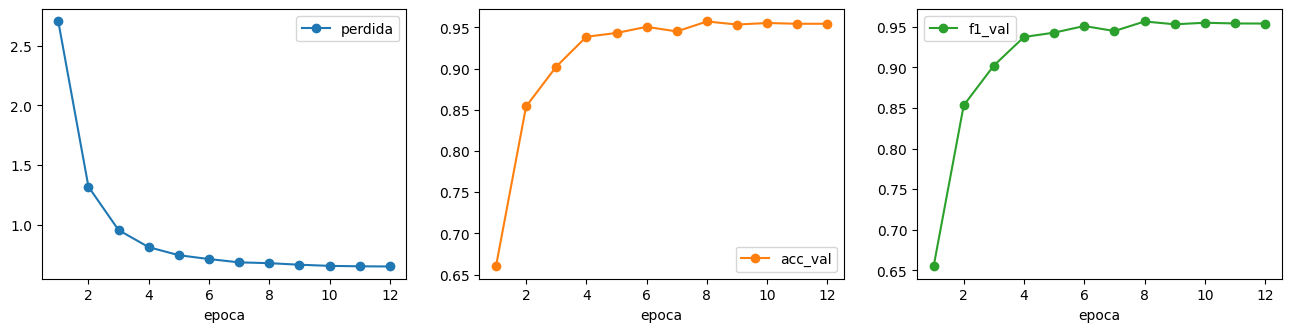

In [12]:
EPOCAS = 12
opt = torch.optim.AdamW(convnext.parameters(), lr=1e-4, weight_decay=0.05)
pasos = EPOCAS * len(dl_tr)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-4, total_steps=pasos, pct_start=0.1, anneal_strategy='cos')
crit = nn.CrossEntropyLoss(label_smoothing=0.1)
scaler = torch.amp.GradScaler('cuda', enabled=(device == 'cuda'))
hist, mejor_f1 = [], -1
for ep in range(1, EPOCAS + 1):
    convnext.train(); perdida = 0
    for x, y in dl_tr:
        x, y = x.to(device), y.to(device)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device == 'cuda')):
            loss = crit(convnext(x), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        perdida += loss.item()
    pv = probas(convnext, dl_va, tta=False).argmax(1)
    f1v, accv = f1_score(y_va, pv, average='macro'), accuracy_score(y_va, pv)
    hist.append((ep, perdida / len(dl_tr), accv, f1v))
    print(f'Época {ep:2d} | pérdida {perdida/len(dl_tr):.4f} | acc val {accv:.4f} | F1 val {f1v:.4f}')
    if f1v > mejor_f1:
        mejor_f1 = f1v; torch.save(convnext.state_dict(), 'convnext_best.pt')
convnext.load_state_dict(torch.load('convnext_best.pt'))
h = pd.DataFrame(hist, columns=['epoca', 'perdida', 'acc_val', 'f1_val']).set_index('epoca')
h.plot(subplots=True, layout=(1, 3), figsize=(16, 3.5), marker='o'); plt.show()

In [13]:
P_va_B, P_te_B = probas(convnext, dl_va), probas(convnext, dl_te)
print('Validación modelo B:', {k: round(v, 4) for k, v in metricas(y_va, P_va_B.argmax(1)).items()})

Validación modelo B: {'Accuracy': 0.9526, 'Precision (macro)': 0.9537, 'Recall (macro)': 0.9522, 'F1 (macro)': 0.9522}


## 6. Ensemble (soft voting ponderado)

$$ P_{ens} = w \cdot P_{CLIP} + (1-w) \cdot P_{ConvNeXt} $$

El peso $w$ se elige maximizando el F1 macro en **validación**; luego se evalúa una sola vez en test.

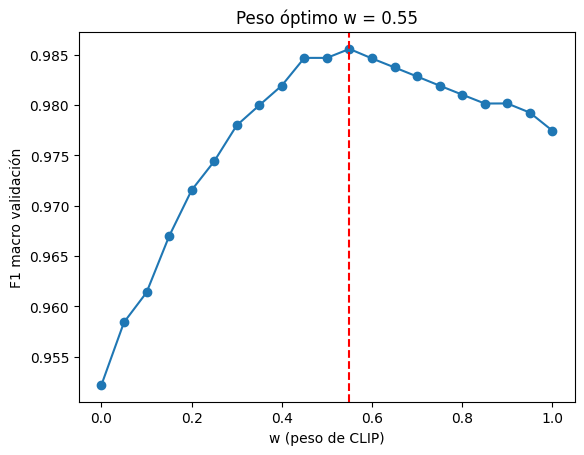

In [14]:
ws = np.round(np.arange(0, 1.01, 0.05), 2)
f1s = [f1_score(y_va, (w * P_va_A + (1 - w) * P_va_B).argmax(1), average='macro') for w in ws]
W = ws[int(np.argmax(f1s))]
plt.plot(ws, f1s, marker='o'); plt.axvline(W, color='r', ls='--')
plt.xlabel('w (peso de CLIP)'); plt.ylabel('F1 macro validación'); plt.title(f'Peso óptimo w = {W}'); plt.show()
P_te_E = W * P_te_A + (1 - W) * P_te_B

## 7. Evaluación final en el conjunto de prueba

In [15]:
tabla = pd.DataFrame({
    'A. CLIP ViT-L/14 + LogReg': metricas(y_te, P_te_A.argmax(1)),
    'B. ConvNeXt-Small fine-tuned': metricas(y_te, P_te_B.argmax(1)),
    f'ENSEMBLE (w={W})': metricas(y_te, P_te_E.argmax(1)),
    'Ref. CLIP zero-shot': metricas(y_te, pred_zs),
}).T.round(4)
display(tabla)
fin = tabla.loc[f'ENSEMBLE (w={W})']
print(f"Recall macro = {fin['Recall (macro)']:.4f}  -> {'CUMPLE' if fin['Recall (macro)'] > 0.9 else 'NO CUMPLE'} (> 0.9)")
print(f"F1 macro     = {fin['F1 (macro)']:.4f}  -> {'CUMPLE' if fin['F1 (macro)'] > 0.9 else 'NO CUMPLE'} (> 0.9)")

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
A. CLIP ViT-L/14 + LogReg,0.9610,0.9600,0.9589,0.9592
B. ConvNeXt-Small fine-tuned,0.9359,0.9367,0.9330,0.9341
ENSEMBLE (w=0.55),0.9703,0.9695,0.9675,0.9682
Ref. CLIP zero-shot,0.9127,0.9167,0.9095,0.9100


Recall macro = 0.9675  -> CUMPLE (> 0.9)
F1 macro     = 0.9682  -> CUMPLE (> 0.9)


In [16]:
pred_te = P_te_E.argmax(1)
print(classification_report(y_te, pred_te, target_names=NOMBRES, digits=3))

                      precision    recall  f1-score   support

Alessandro Del Piero      0.940     0.922     0.931        51
     Andreas Iniesta      1.000     1.000     1.000        50
   Andriy Shevchenko      0.944     0.981     0.962        52
   Cristiano Ronaldo      0.981     1.000     0.990        52
       Didier Drogba      1.000     0.980     0.990        50
      Diego Maradona      0.978     0.918     0.947        49
      Edinson Cavani      1.000     1.000     1.000        50
     Francesco Totti      0.980     1.000     0.990        50
     Gianlugi Buffon      0.981     0.981     0.981        52
       Iker Casillas      1.000     1.000     1.000        52
        Lionel Messi      0.940     0.940     0.940        50
         Luka Modric      1.000     1.000     1.000        53
       Mohamed Salah      1.000     1.000     1.000        52
        Pavel Nedved      0.941     0.889     0.914        36
                Pele      0.943     0.917     0.930        36
       

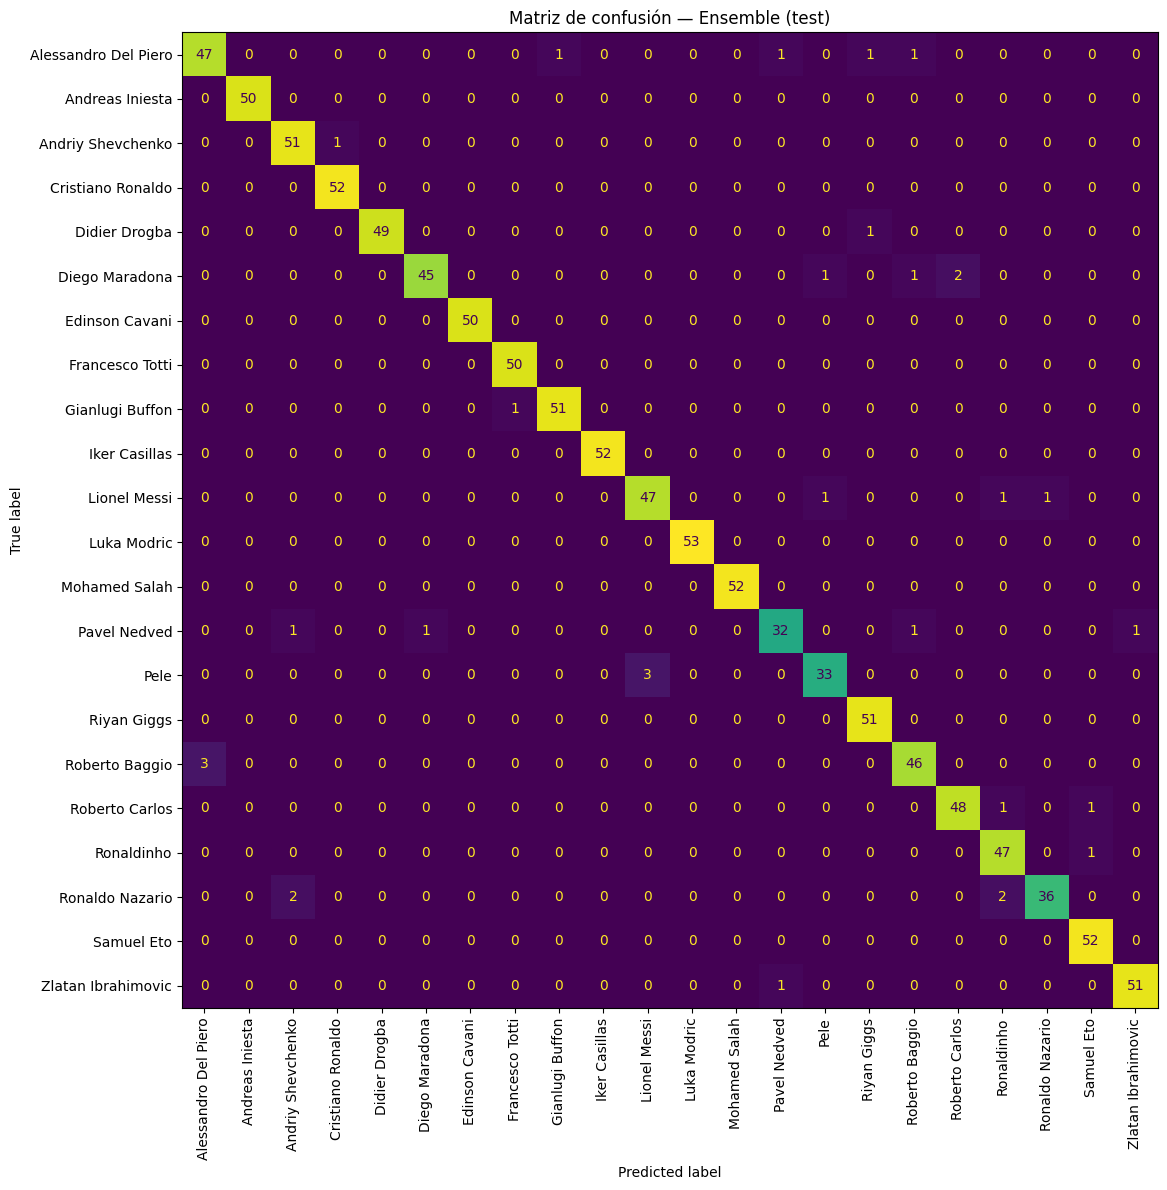

In [17]:
fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_te), display_labels=NOMBRES).plot(ax=ax, xticks_rotation=90, colorbar=False)
ax.set_title('Matriz de confusión — Ensemble (test)'); plt.tight_layout(); plt.show()

Errores en test: 32 de 1077


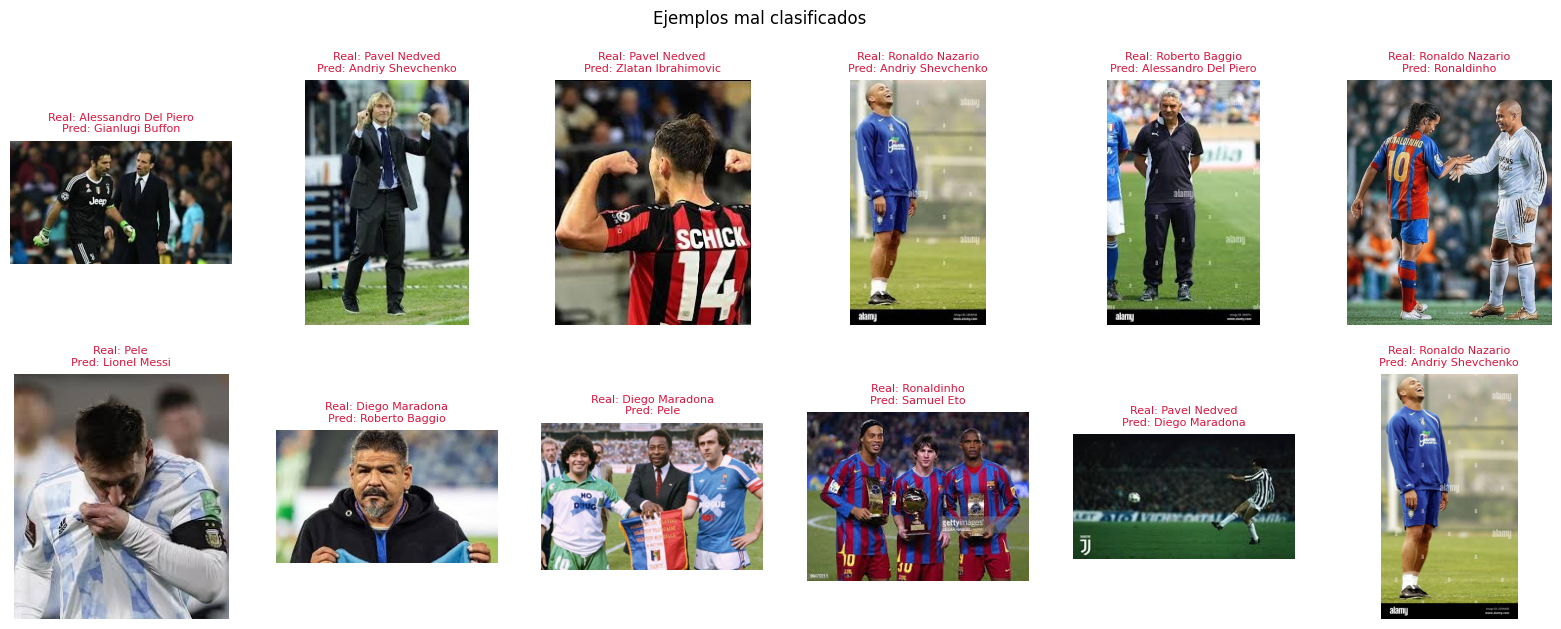

In [18]:
err = np.where(pred_te != y_te)[0]
print(f'Errores en test: {len(err)} de {len(y_te)}')
fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for ax, i in zip(axes.ravel(), err[:12]):
    ax.imshow(Image.open(te_df.path.values[i]).convert('RGB'))
    ax.set_title(f'Real: {NOMBRES[y_te[i]]}\nPred: {NOMBRES[pred_te[i]]}', fontsize=8, color='crimson'); ax.axis('off')
for ax in axes.ravel()[len(err[:12]):]: ax.axis('off')
plt.suptitle('Ejemplos mal clasificados'); plt.show()

## 8. Uso del modelo: predicción de una imagen nueva

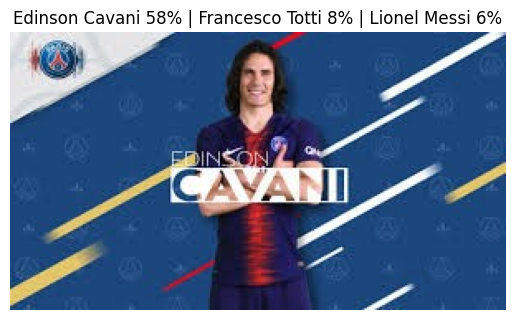

In [19]:
@torch.no_grad()
def predecir(ruta_img, top=3):
    img = Image.open(ruta_img).convert('RGB')
    xa = clip_pre(img).unsqueeze(0).to(device)
    with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(device == 'cuda')):
        fa = clip_model.encode_image(xa) + clip_model.encode_image(torch.flip(xa, dims=[3]))
    pa = clf_clip.predict_proba(torch.nn.functional.normalize(fa.float(), dim=-1).cpu().numpy())
    pb = probas(convnext, [(tf_eval(img).unsqueeze(0), None)])
    p = (W * pa + (1 - W) * pb)[0]
    orden = p.argsort()[::-1][:top]
    plt.imshow(img); plt.axis('off'); plt.title(' | '.join(f'{NOMBRES[k]} {p[k]:.0%}' for k in orden)); plt.show()

predecir(te_df.path.values[0])

## 9. Conclusiones

1. **Datos:** 22 jugadores, ≈7 200 imágenes muy heterogéneas. El CSV se usó para relacionar cada archivo con su
   jugador; se eliminaron duplicados con etiquetas contradictorias para evitar ruido y fuga entre train y test.
2. **Por qué transfer learning:** con ~300 imágenes por clase y tanta variabilidad, entrenar una CNN desde cero no
   alcanza el rendimiento requerido. Los modelos preentrenados aportan representaciones visuales generales aprendidas
   de millones de imágenes.
3. **Modelo en conjunto:** CLIP (Transformer, conocimiento semántico, clasificador lineal) y ConvNeXt (CNN afinada
   con aumento de datos) tienen arquitecturas y entrenamientos distintos, por lo que sus errores están poco
   correlacionados; el promedio ponderado (*soft voting*) aprovecha esa complementariedad (comparar las filas A, B y
   ENSEMBLE de la tabla de la sección 7).
4. **Resultados:** la tabla de la sección 7 muestra Recall macro y F1 macro del ensemble sobre el conjunto de prueba,
   que no se usó en ninguna decisión de entrenamiento. Ambos deben superar 0.9.
5. **Errores típicos:** fotos con varias personas, imágenes donde el jugador aparece muy pequeño o de espaldas,
   y fotos antiguas de baja calidad (ver la sección de ejemplos mal clasificados).